In [1]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import DBSCAN
import re
from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

In [2]:
data = pd.read_csv('/Users/nicolasbour/Desktop/Projets_IA/Projets_certif/bloc_03_Machine_Learning/03_the_north_face/Nico/sample_clean.csv')

In [3]:
data.head()

,id,description_texte,details,fabric,weight,pays
0,1,active classic boxers - s reason boxers cult f...,"silky capilene 1 fabric ultralight , breathabl...",3.7 - oz 100 % - recycled polyester gladiodor ...,99 g 3.5 oz,Mexico
1,2,active sport boxer briefs - skinning glory req...,"stretch mesh provides support , open - weave m...",4.6 - oz 93 % polyester 71 % recycled /7 % spa...,60 g 2.1 oz,Israel
2,3,active sport briefs - superbreathable - fly br...,"stretch mesh provides support , open - weave m...",4.6 - oz 93 % polyester 71 % recycled /7 % spa...,49 g 1.7 oz,Israel
3,4,"alpine guide pants - skin , climb ice , switch...",durable stretch - woven polyester 47 % recycle...,7.6 - oz 90 - denier 92 % polyester 47 % recyc...,597 g 20.7 oz,Vietnam
4,5,"alpine wind jkt - high ridges , steep ice alpi...","lightweight , breathable polyester ripstop fab...",shell 1.3 - oz 20 - denier 100 % polyester rip...,331 g 11.5 oz,China


In [4]:
data.isnull().sum()

id                   0
description_texte    0
details              0
fabric               0
weight               8
pays                 8
dtype: int64

In [5]:
data.nunique()

id                   500
description_texte    488
details              420
fabric               223
weight               243
pays                  12
dtype: int64

In [6]:
data.shape

(500, 6)

In [10]:
colonnes_texte = ["description_texte", "details", "fabric", "weight", "pays"]

textes = data[colonnes_texte].fillna("").astype(str).agg(" ".join, axis=1)


In [11]:
display(textes.head())
print("Nombre de textes :", len(textes))

0    active classic boxers - s reason boxers cult f...
1    active sport boxer briefs - skinning glory req...
2    active sport briefs - superbreathable - fly br...
3    alpine guide pants - skin , climb ice , switch...
4    alpine wind jkt - high ridges , steep ice alpi...
dtype: object

Nombre de textes : 500


In [12]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_df=0.95,
    min_df=2
)

matrice_tfidf = vectorizer.fit_transform(textes)

print("Dimensions :", matrice_tfidf.shape)
print("Exemples de mots :", vectorizer.get_feature_names_out()[:20])

Dimensions : (500, 2619)
Exemples de mots : ['000' '10' '100' '103' '108' '109' '1096' '11' '112' '115' '118' '1188'
 '12' '1200' '121' '124' '126' '129' '13' '130']


In [13]:
pd.DataFrame(
    matrice_tfidf[:5].toarray(),
    columns=vectorizer.get_feature_names_out()
)

,000,10,100,103,108,109,1096,11,112,115,...,yoga,yoke,yosemite,zip,zipper,zippered,zippers,zipping,zips,zones
0,0.0,0.00000,0.082345,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,0.0,0.00000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,0.0,0.00000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,0.0,0.00000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.239127,0.073411,0.0,0.0,0.0
4,0.0,0.04785,0.047210,0.0,0.0,0.0,0.0,0.060475,0.0,0.0,...,0.0,0.0,0.0,0.0,0.089452,0.035530,0.054538,0.0,0.0,0.0


In [14]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=10,
    metric="cosine"
)

In [15]:
data["cluster"] = dbscan.fit_predict(matrice_tfidf)

display(data["cluster"].value_counts().sort_index())

cluster
-1    420
 0     10
 1     55
 2     15
Name: count, dtype: int64

In [16]:
display(data.sort_values("cluster"))

,id,description_texte,details,fabric,weight,pays,cluster
0,1,active classic boxers - s reason boxers cult f...,"silky capilene 1 fabric ultralight , breathabl...",3.7 - oz 100 % - recycled polyester gladiodor ...,99 g 3.5 oz,Mexico,-1
325,326,thrift shorts - unofficial short wander aimles...,cool - wearing recycled polyester organic cott...,3.4 - oz 65 % - recycled polyester/35 % organi...,207 g 7.2 oz,Thailand,-1
324,325,wavefarer board shorts - wavefarers won t bunc...,"nylon fabric lightweight , durable quick - dry...",4.3 - oz 100 % nylon dwr durable water repelle...,121 g 4.2 oz,Thailand,-1
323,324,vitalti pants - soft stretchy vitaliti pants t...,plaited organic cotton polyester stretch fabri...,5.7 - oz 55 % organic cotton/35 % - recycled p...,377 g 13.1 oz,Thailand,-1
322,323,vitaliti vee - stretch refined drape vitaliti ...,plaited organic cotton - recycled - polyester ...,5.7 - oz 55 % organic cotton/35 % - recycled p...,129 g 4.5 oz,Thailand,-1
...,...,...,...,...,...,...,...
86,87,"merino 1 crew - day packed decisions , s easy ...",slow - washed merino wool resists odor natural...,3.2 - oz 108 - g 63 % 16.5 micron chlorine - f...,138 g 4.9 oz,USA,2
268,269,merino 2 t - shirt - versatile merino baselaye...,slow - washed merino wool resists odor natural...,4.85 - oz 165 - g 73 % chlorine - free merino ...,103 g 3.6 oz,USA,2
405,406,"merino 2 bottoms - stop - - pace , like alpine...",slow - washed merino wool resists odor natural...,4.85 - oz 165 - g 73 % chlorine - free merino ...,170 g 5.9 oz,USA,2
201,202,merino 2 crew - moved people culture new place...,slow - washed merino wool resists odor natural...,4.85 - oz 165 - g 73 % chlorine - free merino ...,150 g 5.2 oz,USA,2


In [17]:
print(f"Nombre de clusters : {len(set(data['cluster'])) - 1}")  # On soustrait 1 pour exclure le bruit (-1)

Nombre de clusters : 3


Le cluster -1 est le cluster considéré comme du bruit par l'algorithme Dbscan. Nous allons tenter de réduire le nombre de produits dans ce cluster en ajustant les paramètres de l'algorithme.

In [18]:
parametres = {
    "eps": [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "min_samples": [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15]
}

resultats = []

for params in ParameterGrid(parametres):
    clusters = DBSCAN(**params, metric="cosine").fit_predict(matrice_tfidf)
    sans_bruit = clusters != -1
    try : 
        score = silhouette_score(
            matrice_tfidf[sans_bruit],
            clusters[sans_bruit],
            metric="cosine"
        )
    except ValueError:
        score = np.nan

    resultats.append({
        **params,
        "silhouette": score,
        "%_bruit": (1 - sans_bruit.mean()) * 100,
        "nb_clusters": len(set(clusters)) - (1 if -1 in clusters else 0)
    })

resultats = pd.DataFrame(resultats)
display(resultats.sort_values("nb_clusters", ascending=False))

,eps,min_samples,silhouette,%_bruit,nb_clusters
0,0.4,2,0.602377,34.2,97
11,0.5,2,0.497565,24.2,96
22,0.6,2,0.347109,10.0,81
23,0.6,3,0.336611,24.0,46
12,0.5,3,0.482456,47.4,38
...,...,...,...,...,...
55,0.9,2,NaN,0.0,1
53,0.8,12,NaN,5.4,1
52,0.8,10,NaN,4.6,1
51,0.8,9,NaN,4.2,1


In [19]:
candidats = resultats[(resultats["nb_clusters"] <= 20) & (resultats["nb_clusters"] >= 10) & resultats["silhouette"].notna()]

In [20]:
display(candidats)

,eps,min_samples,silhouette,%_bruit,nb_clusters
2,0.4,4,0.564616,67.8,20
3,0.4,5,0.552526,74.4,12
14,0.5,5,0.483524,64.8,16
15,0.5,6,0.478959,70.2,11
26,0.6,6,0.382610,53.4,16
27,0.6,7,0.394457,59.2,12
28,0.6,8,0.403620,63.8,10
34,0.7,3,0.137630,4.8,17
35,0.7,4,0.146278,7.0,16
36,0.7,5,0.162678,11.8,12


In [21]:
if candidats.empty:
    print("Aucun modèle valide avec au maximum 20 clusters.")
else:
    meilleur = candidats.sort_values("silhouette", ascending=False).iloc[0]
    display(meilleur)

eps             0.400000
min_samples     4.000000
silhouette      0.564616
%_bruit        67.800000
nb_clusters    20.000000
Name: 2, dtype: float64

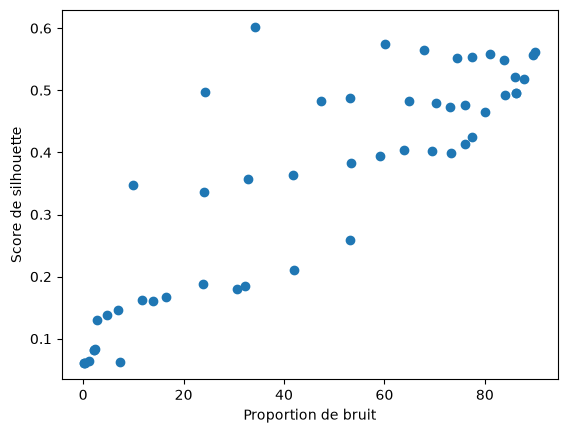

In [22]:
import matplotlib.pyplot as plt

plt.scatter(resultats["%_bruit"], resultats["silhouette"])
plt.xlabel("Proportion de bruit")
plt.ylabel("Score de silhouette")
plt.show()